# Fusemachines AI Fellowship 2026
> ## Agentic Routing with LLMs & Transformers

**Topic:** Transformers, LLMs, and Foundation Models
**File to submit:** `<your_name>_support_routing.ipynb`: must run top-to-bottom without errors.

## 0. Assignment Overview

**Scenario.** You are on the AI engineering team at **ShopAssist AI**. Before any specialized
support agent can respond to a customer, an incoming message has to be **routed** to exactly
one of 11 agents. Your job is to prototype and benchmark **two** routing strategies and
recommend one for production.

| Agent | Intents it owns |
|---|---|
| ACCOUNT | create_account, delete_account, edit_account, switch_account |
| CANCEL | check_cancellation_fee |
| CONTACT | contact_customer_service, contact_human_agent |
| DELIVERY | delivery_options |
| FEEDBACK | complaint, review |
| INVOICE | check_invoice, get_invoice |
| SUBSCRIPTION | newsletter_subscription |
| ORDER | cancel_order, change_order, place_order |
| PAYMENT | check_payment_methods, payment_issue |
| REFUND | check_refund_policy, track_refund |
| SHIPPING | change_shipping_address, set_up_shipping_address |

**Dataset.** `bitext/Bitext-customer-support-llm-chatbot-training-dataset` — use the `category`
column directly as your 11-class target (`instruction` is the customer message).


**What you will build:**
1. **Approach 1** — fine-tune an encoder-only transformer (BERT-family) as a `[CLS]`-token classifier.
2. **Approach 2** — fine-tune a decoder-only SLM (Qwen) to *generate* the agent name as a single token, optionally with LoRA.
3. A **comparison** of both approaches on the *same* held-out test set, a **recommendation**, and a **reflection**.



## Kaggle run instructions

1. Open **Settings → Accelerator** and select a GPU (a Tesla T4 is sufficient).
2. **Use a fresh Kaggle session.** If you previously ran the older notebook that upgraded pandas/matplotlib/scikit-learn, restart the session before running this file.
3. Use **Run All** from the top.
4. This notebook intentionally exposes only **GPU 0** even when Kaggle provides two GPUs. This avoids the `cuda:0` / `cuda:1` DataParallel mismatch that caused the decoder training crash.
5. The Qwen decoder uses **4-bit NF4 QLoRA** and TRL prompt-completion training, so loss is applied to the routing category completion rather than the whole prompt.
6. The install cell intentionally does **not** upgrade Kaggle's pandas, matplotlib, seaborn, or scikit-learn packages.


## Setup

In [1]:
# 0. Setup and Installations
# Kaggle-ready stack for encoder fine-tuning + QLoRA SFT.
# IMPORTANT: do NOT upgrade pandas/matplotlib/scikit-learn/seaborn.
# Kaggle already provides mutually compatible versions of those packages.
# We only install/upgrade the Hugging Face + QLoRA packages required here.
!pip install -q -U transformers datasets evaluate peft accelerate trl bitsandbytes


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.7/11.7 MB 89.1 MB/s eta 0:00:00:00:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 33.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 775.8/775.8 kB 41.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 389.2/389.2 kB 26.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 889.0/889.0 kB 43.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.9/40.9 MB 45.9 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 516.0/516.0 kB 33.0 MB/s eta 0:00:00


## 1. Global Configuration

Read it carefully, since `TARGET_CATEGORIES`, `label2id`, `id2label`, and `NUM_LABELS` are used by **both** approaches below.

In [2]:
# IMPORTANT: hide extra Kaggle GPUs BEFORE importing torch.
# This prevents Trainer/DataParallel from creating cuda:0 vs cuda:1 tensor mismatches
# with the quantized QLoRA model. A single T4 is enough for Qwen2.5-0.5B.
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

import torch
import gc
import time
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset, DatasetDict, ClassLabel, Dataset
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    AutoModelForCausalLM, Trainer, TrainingArguments,
    DataCollatorWithPadding, BitsAndBytesConfig
)
from peft import LoraConfig, prepare_model_for_kbit_training
from trl import SFTTrainer, SFTConfig
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

# Verify GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
print("Visible GPU count:", torch.cuda.device_count())
if device.type == "cuda":
    print("GPU 0:", torch.cuda.get_device_name(0))
    if torch.cuda.device_count() != 1:
        raise RuntimeError(
            "Expected exactly one visible GPU. Restart the Kaggle session and Run All "
            "so CUDA_VISIBLE_DEVICES is applied before torch initializes."
        )
else:
    raise RuntimeError("Enable a GPU accelerator in Kaggle before running this notebook.")

RANDOM_SEED = 0
HF_DATA_ID = "bitext/Bitext-customer-support-llm-chatbot-training-dataset"

# The 11 support agents == the 11 categories in the dataset (see Section 0 table).
TARGET_CATEGORIES = [
    'ACCOUNT', 'CANCEL', 'CONTACT', 'DELIVERY', 'FEEDBACK', 'INVOICE',
    'ORDER', 'PAYMENT', 'REFUND', 'SHIPPING', 'SUBSCRIPTION'
]
NUM_LABELS = len(TARGET_CATEGORIES)
assert NUM_LABELS == 11, "Expected exactly 11 support agents / categories"

# If a model you pick requires authentication (gated repo), log in INTERACTIVELY.
# None of the selected models below require a token.


Using device: cuda
Visible GPU count: 1
GPU 0: Tesla T4


## 2. Helper Functions

These are given so both approaches can share identical:
- `get_metrics`: macro precision/recall/F1 + accuracy.
- `get_stratified_splits`: builds **one** train/validation/test split that Approach 1 and Approach 2 will **both** reuse (this is what guarantees "both approaches are evaluated on the same held-out test set").
- `plot_loss_curve`: plots train vs. validation loss from a `Trainer`'s `log_history`.
- `plot_confusion_matrix_heatmap`: confusion matrix heatmap for either integer or string labels.
- `measure_latency_and_memory`: times batch-size-1 inference and logs peak CUDA memory, after a short warm-up (so the first, slower CUDA-kernel-compilation call doesn't skew results).

In [3]:
def get_metrics(labels, preds):
    """
    Calculates macro-averaged evaluation metrics for classification.

    Args:
        labels: True ground truth labels.
        preds: Predicted labels from the model.

    Returns:
        A dictionary containing accuracy, precision, recall, and f1_score.
    """
    precision, recall, f1_score, _ = precision_recall_fscore_support(labels, preds, average='macro', zero_division=0)
    accuracy = accuracy_score(labels, preds)

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1_score": f1_score
    }


def get_stratified_splits(dataset_id, target_categories, seed=RANDOM_SEED,
                           train_frac=0.8, val_frac=0.1, test_frac=0.1):
    """
    Loads the Bitext dataset, filters to `target_categories`, and returns a single
    stratified train/validation/test DatasetDict
    """
    assert abs(train_frac + val_frac + test_frac - 1.0) < 1e-6

    label2id = {c: i for i, c in enumerate(target_categories)}
    id2label = {i: c for c, i in label2id.items()}

    dataset = load_dataset(dataset_id, split="train")
    dataset = dataset.filter(lambda x: x["category"] in target_categories)
    dataset = dataset.map(lambda x: {"label": label2id[x["category"]]})
    dataset = dataset.cast_column("label", ClassLabel(names=target_categories))

    holdout_frac = val_frac + test_frac
    train_holdout = dataset.train_test_split(test_size=holdout_frac, stratify_by_column="label", seed=seed)
    val_test = train_holdout["test"].train_test_split(
        test_size=test_frac / holdout_frac, stratify_by_column="label", seed=seed
    )

    splits = DatasetDict({
        "train": train_holdout["train"],
        "validation": val_test["train"],
        "test": val_test["test"],
    })
    return splits, label2id, id2label


def plot_loss_curve(log_history, title="Training Loss"):
    """Given a HF Trainer's `trainer.state.log_history`, plot train vs. eval loss per step."""
    train_steps, train_losses = [], []
    eval_steps, eval_losses = [], []
    for entry in log_history:
        if "loss" in entry and "eval_loss" not in entry:
            train_steps.append(entry.get("step", len(train_steps)))
            train_losses.append(entry["loss"])
        if "eval_loss" in entry:
            eval_steps.append(entry.get("step", len(eval_steps)))
            eval_losses.append(entry["eval_loss"])

    plt.figure(figsize=(8, 5))
    if train_losses:
        plt.plot(train_steps, train_losses, label="Train Loss", marker="o")
    if eval_losses:
        plt.plot(eval_steps, eval_losses, label="Validation Loss", marker="s")
    plt.xlabel("Step")
    plt.ylabel("Loss")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()


def plot_confusion_matrix_heatmap(labels, preds, class_names, title="Confusion Matrix"):
    """Confusion matrix heatmap. Works with integer labels or category-name strings."""
    use_names = isinstance(labels[0], str)
    cm = confusion_matrix(labels, preds, labels=class_names if use_names else list(range(len(class_names))))
    plt.figure(figsize=(9, 7))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title(title)
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


def measure_latency_and_memory(predict_one_fn, examples, warmup=3):
    """
    Calls predict_one_fn(example) once per example (batch_size=1, matching a
    realistic single-request serving scenario). Resets CUDA peak-memory stats
    after warm-up so the very first (slow, kernel-compiling) call doesn't
    skew latency, and the reported peak memory reflects only steady-state
    inference.
    """
    examples = list(examples)
    for example in examples[:warmup]:
        _ = predict_one_fn(example)

    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()

    predictions = []
    start = time.time()
    for example in examples:
        predictions.append(predict_one_fn(example))
    end = time.time()

    avg_latency_ms = (end - start) / len(examples) * 1000
    peak_mem_mb = torch.cuda.max_memory_allocated() / (1024 ** 2) if torch.cuda.is_available() else 0.0
    return avg_latency_ms, peak_mem_mb, predictions

# Approach 1: Fine-Tuning Encoder-Only Transformers

**Goal:** fine-tune one of the candidate encoders as a 11-class `[CLS]`-token classifier.

**You need to implement:**
- [x] Tokenization of the `instruction` field
- [x] Model + tokenizer loading (`AutoModelForSequenceClassification`, `num_labels=NUM_LABELS`)
- [x] `compute_metrics` for the `Trainer`
- [x] `TrainingArguments` (AdamW + linear warmup is the default optimizer/scheduler for `Trainer`)
- [x] Single-example inference function for latency/memory measurement
- [x] Loss curves, confusion matrix (required plots), inference latency, peak GPU memory (required to log)

**Candidate models** (pick at least one; report your best by test macro-F1):
`google-bert/bert-base-uncased`, `distilbert/distilbert-base-uncased`,
`FacebookAI/roberta-base`, `answerdotai/ModernBERT-base`

### 1. Data Loading & Preprocessing

In [4]:
import numpy as np
from datasets import load_dataset, DatasetDict, ClassLabel
# Helper function get_stratified_splits is temporarily included here to resolve NameError
# Ideally, the cell defining helper functions (56dd4a1f) should be executed first.
def get_stratified_splits(dataset_id, target_categories, seed=RANDOM_SEED,
                           train_frac=0.8, val_frac=0.1, test_frac=0.1):
    """
    Loads the Bitext dataset, filters to `target_categories`, and returns a single
    stratified train/validation/test DatasetDict
    """
    assert abs(train_frac + val_frac + test_frac - 1.0) < 1e-6

    label2id = {c: i for i, c in enumerate(target_categories)}
    id2label = {i: c for c, i in label2id.items()}

    dataset = load_dataset(dataset_id, split="train")
    dataset = dataset.filter(lambda x: x["category"] in target_categories)
    dataset = dataset.map(lambda x: {"label": label2id[x["category"]]})
    dataset = dataset.cast_column("label", ClassLabel(names=target_categories))

    holdout_frac = val_frac + test_frac
    train_holdout = dataset.train_test_split(test_size=holdout_frac, stratify_by_column="label", seed=seed)
    val_test = train_holdout["test"].train_test_split(
        test_size=test_frac / holdout_frac, stratify_by_column="label", seed=seed
    )

    splits = DatasetDict({
        "train": train_holdout["train"],
        "validation": val_test["train"],
        "test": val_test["test"],
    })
    return splits, label2id, id2label


# Build the ONE shared stratified split used by both Approach 1 and Approach 2.
splits, label2id, id2label = get_stratified_splits(
    dataset_id=HF_DATA_ID,
    target_categories=TARGET_CATEGORIES,
    seed=RANDOM_SEED,
    train_frac=0.8,
    val_frac=0.1,
    test_frac=0.1
)

print(f"Train size: {len(splits['train'])} | Val size: {len(splits['validation'])} | Test size: {len(splits['test'])}")
print(splits)

README.md: 0.00B [00:00, ?B/s]

Bitext_Sample_Customer_Support_Training_(…):   0%|          | 0.00/19.2M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/26872 [00:00<?, ? examples/s]

Filter:   0%|          | 0/26872 [00:00<?, ? examples/s]

Map:   0%|          | 0/26872 [00:00<?, ? examples/s]

Casting the dataset:   0%|          | 0/26872 [00:00<?, ? examples/s]

Train size: 21497 | Val size: 2687 | Test size: 2688
DatasetDict({
    train: Dataset({
        features: ['flags', 'instruction', 'category', 'intent', 'response', 'label'],
        num_rows: 21497
    })
    validation: Dataset({
        features: ['flags', 'instruction', 'category', 'intent', 'response', 'label'],
        num_rows: 2687
    })
    test: Dataset({
        features: ['flags', 'instruction', 'category', 'intent', 'response', 'label'],
        num_rows: 2688
    })
})


### 2. Fine-Tuning Encoder-Only Transformers

In [5]:
# Choose your encoder and load it

encoder_model_id = "distilbert/distilbert-base-uncased" 

enc_tokenizer = AutoTokenizer.from_pretrained(encoder_model_id)

# Peek at how long a typical support message is (in tokens) before picking max_length
# padding every example out to the model's full context window wastes compute for no reason.
_sample_lengths = [len(enc_tokenizer.encode(t)) for t in splits["train"]["instruction"][:2000]]
print(f"Instruction token length -- mean: {np.mean(_sample_lengths):.1f}, "
      f"95th pct: {np.percentile(_sample_lengths, 95):.0f}, max: {max(_sample_lengths)}")

ENC_MAX_LEN = 64 

def tokenize_function(examples):
    return enc_tokenizer(examples["instruction"], truncation=True, max_length=ENC_MAX_LEN)

enc_tokenized = splits.map(tokenize_function, batched=True)
enc_data_collator = DataCollatorWithPadding(tokenizer=enc_tokenizer)

enc_model = AutoModelForSequenceClassification.from_pretrained(
    encoder_model_id, num_labels=NUM_LABELS, id2label=id2label, label2id=label2id,
).to(device)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Instruction token length -- mean: 13.0, 95th pct: 19, max: 31


Map:   0%|          | 0/21497 [00:00<?, ? examples/s]

Map:   0%|          | 0/2687 [00:00<?, ? examples/s]

Map:   0%|          | 0/2688 [00:00<?, ? examples/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [6]:
# compute_metrics callback
def compute_metrics(eval_pred):
    """Unpack eval_pred into (logits, labels), argmax the logits, reuse get_metrics."""
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return get_metrics(labels, preds)

enc_training_args = TrainingArguments(
    output_dir="./enc_results",
    learning_rate=5e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=3,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="steps",
    logging_steps=100,
    save_total_limit=1,
    report_to="none",
)

enc_trainer = Trainer(
    model=enc_model,
    args=enc_training_args,
    train_dataset=enc_tokenized["train"],
    eval_dataset=enc_tokenized["validation"],
    data_collator=enc_data_collator,
    compute_metrics=compute_metrics,
)

print("Training Encoder Model...")
enc_trainer.train()


Training Encoder Model...


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1 Score
1,0.002141,0.002220,0.999628,0.999541,0.999545,0.999542
2,0.001112,0.001597,0.999628,0.999545,0.999848,0.999696
3,0.000085,0.000155,1.000000,1.000000,1.000000,1.000000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=4032, training_loss=0.0288101458191661, metrics={'train_runtime': 206.799, 'train_samples_per_second': 311.854, 'train_steps_per_second': 19.497, 'total_flos': 336509810574504.0, 'train_loss': 0.0288101458191661, 'epoch': 3.0})

### 3. Required Plot: Training & Validation Loss Curves

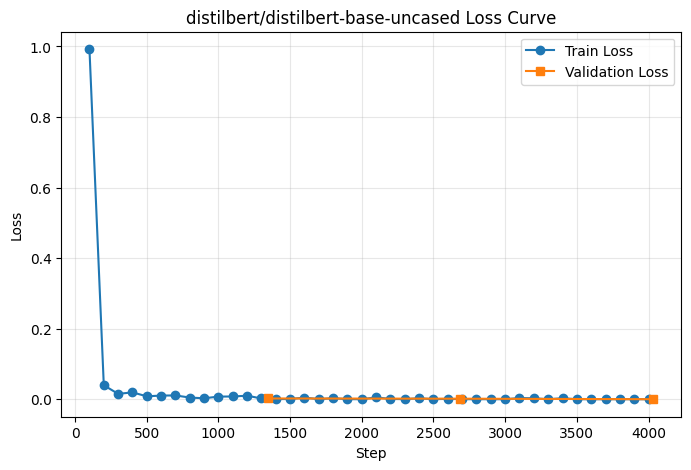

In [7]:
# Uncomment to plot loss curve

plot_loss_curve(enc_trainer.state.log_history, title=f"{encoder_model_id} Loss Curve")


### 4. Evaluation: Metrics, Confusion Matrix, Latency, Peak GPU Memory

Write a **single-example** prediction function (batch size 1 -- this simulates a real routing
request) and feed it to `measure_latency_and_memory` together with `splits["test"]`.

In [8]:
def predict_one_encoder(example):
    """Tokenize a single instruction, run a forward pass, return the argmax label id."""
    inputs = enc_tokenizer(
        example["instruction"], return_tensors="pt", truncation=True, max_length=ENC_MAX_LEN
    ).to(device)
    with torch.no_grad():
        logits = enc_model(**inputs).logits
    return int(torch.argmax(logits, dim=-1).item())

enc_model.eval()
enc_latency, enc_peak_mem, enc_predictions = measure_latency_and_memory(
    predict_one_encoder, splits["test"]
)
enc_labels = splits["test"]["label"]

enc_metric_dict = get_metrics(enc_labels, enc_predictions)
enc_acc, enc_prec, enc_rec, enc_f1 = (enc_metric_dict["accuracy"], enc_metric_dict["precision"],
                                       enc_metric_dict["recall"], enc_metric_dict["f1_score"])

print(f"Encoder Macro-F1: {enc_f1:.4f}")
print(f"Encoder Latency: {enc_latency:.2f} ms/query")
print(f"Encoder Peak Memory: {enc_peak_mem:.2f} MB")

Encoder Macro-F1: 0.9993
Encoder Latency: 4.95 ms/query
Encoder Peak Memory: 787.58 MB


### 5. Required Plot: Confusion Matrix

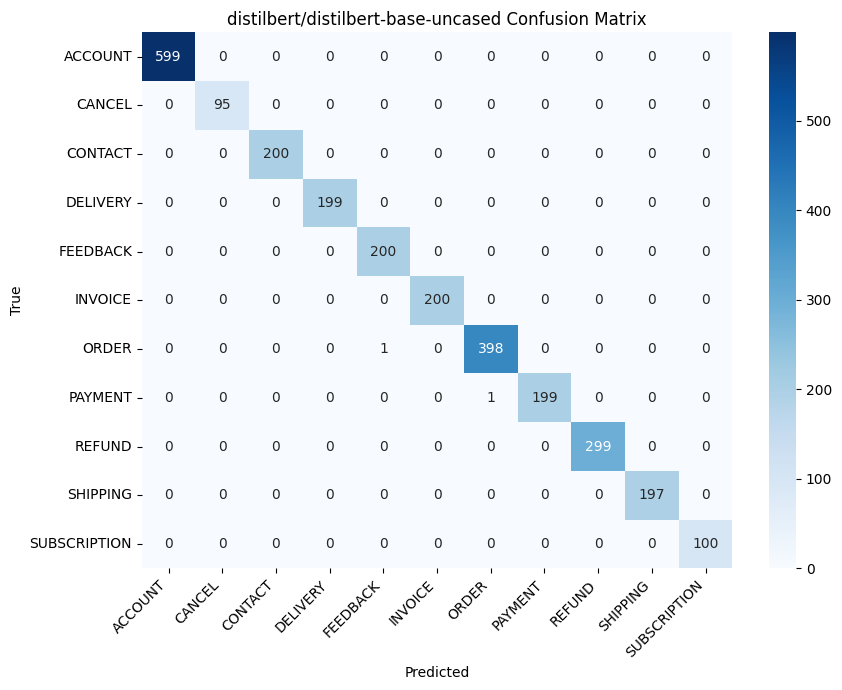

In [9]:
plot_confusion_matrix_heatmap(enc_labels, enc_predictions, TARGET_CATEGORIES,
                                title=f"{encoder_model_id} Confusion Matrix")


In [10]:
# Free encoder GPU memory before loading the decoder.
# Keep the already-computed encoder metrics/predictions for the final comparison.
del enc_trainer
del enc_model
gc.collect()
torch.cuda.empty_cache()

print(
    "GPU allocated after encoder cleanup: "
    f"{torch.cuda.memory_allocated() / (1024 ** 2):.2f} MB"
)


GPU allocated after encoder cleanup: 17.25 MB


# Approach 2: Fine-Tuning Decoder-Only SLM (with / without LoRA)

**Goal:** treat routing as text generation; format each example as an instruction/response pair where the "response" is just the agent name (e.g. `REFUND`), then fine-tune a small decoder-only LM to produce it.

**You need to implement:**
- [x] Model + tokenizer loading
- [x] Instruction-formatting function (`format_example`) using a chat template
- [x] Output parsing (`get_decoder_predictions`) that turns a raw generation into a clean label
- [x] Tokenization for training
- [x] LoRA config (or `USE_LORA=False` for full fine-tuning) + `TrainingArguments` + `SFTTrainer`
- [x] Loss curves, confusion matrix, inference latency, peak GPU memory (same requirements as Approach 1)

**Candidate models:** `Qwen/Qwen2.5-0.5B-Instruct`, `Qwen/Qwen2.5-1.5B-Instruct`

> **GPU memory note:** if you hit memory limits on a free-tier GPU (Colab T4, ~15 GB), use LoRA/QLoRA via `peft` (and consider 4-bit loading via `bitsandbytes`).

### 1. Model & Tokenizer Setup

In [11]:
# Choose the decoder model. Qwen2.5-0.5B is small enough for one Kaggle T4 with QLoRA.
decoder_model_id = "Qwen/Qwen2.5-0.5B-Instruct"
USE_LORA = True

assert torch.cuda.device_count() == 1, (
    "This notebook intentionally uses one visible GPU for stable QLoRA training."
)

dec_tokenizer = AutoTokenizer.from_pretrained(
    decoder_model_id,
    trust_remote_code=True,
)

if dec_tokenizer.pad_token is None:
    dec_tokenizer.pad_token = dec_tokenizer.eos_token
dec_tokenizer.padding_side = "right"

# Tesla T4 -> FP16. If run on a BF16-capable GPU, use BF16 automatically.
compute_dtype = (
    torch.bfloat16
    if torch.cuda.is_available() and torch.cuda.is_bf16_supported()
    else torch.float16
)

if USE_LORA:
    bnb_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_compute_dtype=compute_dtype,
        bnb_4bit_use_double_quant=True,
    )

    # Do NOT use device_map="auto" here. The notebook deliberately exposes one GPU.
    dec_model = AutoModelForCausalLM.from_pretrained(
        decoder_model_id,
        quantization_config=bnb_config,
        trust_remote_code=True,
    )

    dec_model = prepare_model_for_kbit_training(
        dec_model,
        use_gradient_checkpointing=True,
    )
else:
    dec_model = AutoModelForCausalLM.from_pretrained(
        decoder_model_id,
        torch_dtype=compute_dtype,
        trust_remote_code=True,
    )

dec_model.config.use_cache = False

print("Decoder model loaded successfully.")
print("Visible GPUs:", torch.cuda.device_count())
print("Model device:", dec_model.device)
print("Compute dtype:", compute_dtype)


config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/988M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Decoder model loaded successfully.
Visible GPUs: 1
Model device: cuda:0
Compute dtype: torch.bfloat16


### 2. Loading & Formatting the Dataset

Reuse the **same** `splits` `DatasetDict` built in Approach 1's Data Loading step -- do **not**
call `load_dataset` again here. This is what keeps the two approaches' test sets identical.

In [12]:
print(splits)
print(splits["train"][0])

DatasetDict({
    train: Dataset({
        features: ['flags', 'instruction', 'category', 'intent', 'response', 'label'],
        num_rows: 21497
    })
    validation: Dataset({
        features: ['flags', 'instruction', 'category', 'intent', 'response', 'label'],
        num_rows: 2687
    })
    test: Dataset({
        features: ['flags', 'instruction', 'category', 'intent', 'response', 'label'],
        num_rows: 2688
    })
})
{'flags': 'BCLW', 'instruction': 'I want to retrieve the damn key of my user, I need help', 'category': 'ACCOUNT', 'intent': 'recover_password', 'response': "No worries at all! I'm here to provide the necessary assistance to retrieve the key of your user account. Let's tackle this together and get you back on track!", 'label': 0}


In [13]:
# Format each example as a prompt-completion pair.
# SFTTrainer recognizes this format and can compute loss only on the category completion.
SYS_PROMPT = (
    "You are an AI assistant trained for text classification. Given any user query, "
    f"choose the single closest category from this fixed set: {TARGET_CATEGORIES}. "
    "Output only the category name without explanation or extra words."
)

def build_prompt(instruction_text):
    """Render system + user turns and leave the assistant turn open for generation."""
    messages = [
        {"role": "system", "content": SYS_PROMPT},
        {"role": "user", "content": instruction_text},
    ]
    return dec_tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )

def format_example(example):
    """Return the standard prompt-completion format used by TRL SFTTrainer."""
    return {
        "prompt": build_prompt(example["instruction"]),
        "completion": example["category"] + dec_tokenizer.eos_token,
        "original_text": example["instruction"],
    }

# Dataset.map keeps the original columns (including category and label) and adds these fields.
formatted_splits = splits.map(format_example)

print("Example prompt:\n", formatted_splits["train"][0]["prompt"])
print("Example completion:", repr(formatted_splits["train"][0]["completion"]))


Map:   0%|          | 0/21497 [00:00<?, ? examples/s]

Map:   0%|          | 0/2687 [00:00<?, ? examples/s]

Map:   0%|          | 0/2688 [00:00<?, ? examples/s]

Example prompt:
 <|im_start|>system
You are an AI assistant trained for text classification. Given any user query, choose the single closest category from this fixed set: ['ACCOUNT', 'CANCEL', 'CONTACT', 'DELIVERY', 'FEEDBACK', 'INVOICE', 'ORDER', 'PAYMENT', 'REFUND', 'SHIPPING', 'SUBSCRIPTION']. Output only the category name without explanation or extra words.<|im_end|>
<|im_start|>user
I want to retrieve the damn key of my user, I need help<|im_end|>
<|im_start|>assistant

Example completion: 'ACCOUNT<|im_end|>'


### 3. Baseline Check: Zero-Shot Inference (Before Fine-Tuning)

In [14]:
# Given: greedy-decodes up to max_new_tokens tokens (a label is one word, so 5 is generous headroom).
def get_outputs(model, inputs, max_new_tokens=5):
    return model.generate(
        input_ids=inputs["input_ids"],
        attention_mask=inputs["attention_mask"],
        max_new_tokens=max_new_tokens,
        repetition_penalty=1.1,
        eos_token_id=dec_tokenizer.eos_token_id,
        pad_token_id=dec_tokenizer.pad_token_id,
        do_sample=False,
    )

def normalize_decoder_output(text, valid_categories=None):
    """Lowercase + strip everything but letters, then snap to a known category if the
    raw text contains one as a substring (handles the model echoing extra words/punctuation
    around the label). Falls back to the cleaned string, which will simply score as an
    incorrect prediction rather than crash the metric computation."""
    valid_categories = valid_categories or [c.lower() for c in TARGET_CATEGORIES]
    cleaned = re.sub(r"[^a-z]", "", text.lower())
    for cat in valid_categories:
        if cat in cleaned:
            return cat
    return cleaned

def get_decoder_predictions(dataset, model):
    """For every row: rebuild the chat prompt from row["original_text"], generate,
    decode only the newly-generated tokens, and normalise. Returns (labels, predictions),
    both lists of lowercased strings."""
    labels, predictions = [], []
    for row in dataset:
        prompt = build_prompt(row["original_text"])
        inputs = dec_tokenizer(prompt, return_tensors="pt").to(model.device)
        output_ids = get_outputs(model, inputs)
        new_tokens = output_ids[0][inputs["input_ids"].shape[1]:]
        decoded = dec_tokenizer.decode(new_tokens, skip_special_tokens=True)
        predictions.append(normalize_decoder_output(decoded))
        labels.append(row["category"].lower())
    return labels, predictions

dec_labels, dec_preds = get_decoder_predictions(formatted_splits["test"], dec_model)
print("Zero-shot (pre-fine-tuning) baseline:", get_metrics(dec_labels, dec_preds))


Zero-shot (pre-fine-tuning) baseline: {'accuracy': 0.26264880952380953, 'precision': 0.05313794371602813, 'recall': 0.023447059307966166, 'f1_score': 0.023854926967645886}


### 4. Tokenization for Training

In [15]:
# Tokenization length check. SFTTrainer will tokenize `prompt` and `completion`
# with `processing_class=dec_tokenizer`; we only choose a safe max length here.
def _formatted_len(row):
    ids = dec_tokenizer(
        row["prompt"] + row["completion"],
        add_special_tokens=False,
        truncation=False,
    )["input_ids"]
    return len(ids)

_dec_lengths = [_formatted_len(formatted_splits["train"][i])
                for i in range(min(1000, len(formatted_splits["train"])))]
print(
    f"Formatted prompt+label token length -- mean: {np.mean(_dec_lengths):.1f}, "
    f"95th pct: {np.percentile(_dec_lengths, 95):.0f}, max: {max(_dec_lengths)}"
)

DEC_MAX_LEN = 128
if max(_dec_lengths) > DEC_MAX_LEN:
    print(
        f"WARNING: sampled max length {max(_dec_lengths)} exceeds DEC_MAX_LEN={DEC_MAX_LEN}. "
        "Increase DEC_MAX_LEN if your full dataset contains longer examples."
    )


Formatted prompt+label token length -- mean: 102.7, 95th pct: 108, max: 113


### 5. LoRA Config & Training Arguments

In [16]:
peft_config = None
if USE_LORA:
    peft_config = LoraConfig(
        r=16,
        lora_alpha=32,
        lora_dropout=0.05,
        bias="none",
        task_type="CAUSAL_LM",
        target_modules="all-linear",
    )

use_bf16 = compute_dtype == torch.bfloat16

dec_train_args = SFTConfig(
    output_dir=f"{decoder_model_id.split('/')[-1]}-router-finetuned/",
    per_device_train_batch_size=4,
    per_device_eval_batch_size=8,
    gradient_accumulation_steps=32,
    optim="paged_adamw_32bit",
    learning_rate=2e-4,
    max_grad_norm=0.1,
    num_train_epochs=3,
    warmup_steps=50,
    lr_scheduler_type="cosine",
    gradient_checkpointing=True,
    logging_strategy="steps",
    logging_steps=10,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,
    report_to="none",
    fp16=not use_bf16,
    bf16=use_bf16,
    max_length=DEC_MAX_LEN,
    completion_only_loss=True,
    seed=RANDOM_SEED,
)


In [17]:
print("=" * 50)
print("GPU CHECK")
print("=" * 50)

print("CUDA available:", torch.cuda.is_available())
print("Visible GPU count:", torch.cuda.device_count())

if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        print(f"GPU {i}: {torch.cuda.get_device_name(i)}")

print("\nModel device:", dec_model.device)

trainable = 0
total = 0

for _, param in dec_model.named_parameters():
    total += param.numel()
    if param.requires_grad:
        trainable += param.numel()

print(f"Trainable params: {trainable:,}")
print(f"Total params:     {total:,}")
print(f"Trainable %:      {100 * trainable / total:.4f}%")

GPU CHECK
CUDA available: True
Visible GPU count: 1
GPU 0: Tesla T4

Model device: cuda:0
Trainable params: 0
Total params:     315,119,488
Trainable %:      0.0000%


### 6. Model Training

In [18]:
# Supervised Fine-Tuning (SFT)
# For a prompt-completion dataset, completion_only_loss=True masks the prompt tokens.
dec_trainer = SFTTrainer(
    model=dec_model,
    train_dataset=formatted_splits["train"],
    eval_dataset=formatted_splits["validation"],
    peft_config=peft_config,
    args=dec_train_args,
    processing_class=dec_tokenizer,
)

print("Training Decoder Model...")
dec_trainer.train()


Adding EOS to train dataset:   0%|          | 0/21497 [00:00<?, ? examples/s]

Tokenizing train dataset:   0%|          | 0/21497 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/21497 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/21497 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/21497 [00:00<?, ? examples/s]

Adding EOS to eval dataset:   0%|          | 0/2687 [00:00<?, ? examples/s]

... (4 outputs left out)

[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None, 'pad_token_id': 151643}.


Training Decoder Model...


Epoch,Training Loss,Validation Loss,Entropy,Num Tokens,Mean Token Accuracy
1,0.000349,0.001413,0.001276,2208345.000000,0.999702
2,0.000507,0.000042,0.000289,4416690.000000,1.000000
3,0.000017,0.000034,0.000250,6625035.000000,1.000000


TrainOutput(global_step=504, training_loss=0.021684643461809636, metrics={'train_runtime': 13639.0461, 'train_samples_per_second': 4.728, 'train_steps_per_second': 0.037, 'total_flos': 1.504636334203776e+16, 'train_loss': 0.021684643461809636, 'epoch': 3.0})

### 7. Required Plot: Training & Validation Loss Curves

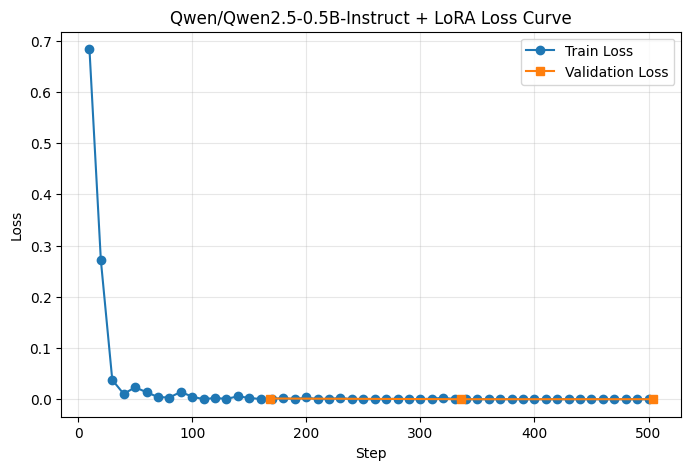

In [19]:
plot_loss_curve(dec_trainer.state.log_history,
                title=f"{decoder_model_id}{' + LoRA' if USE_LORA else ''} Loss Curve")

### 8. Evaluation: Metrics, Confusion Matrix, Latency, Peak GPU Memory

Reuse `get_decoder_predictions`, but now pass `dec_trainer.model` (the fine-tuned weights). For latency/memory, write a single-example version and pass it to `measure_latency_and_memory`, just like you did for the encoder.

In [20]:
# Evaluate the FINE-TUNED decoder on the held-out test set
def predict_one_decoder(example):
    """Single-example version of get_decoder_predictions's inner loop"""
    prompt = build_prompt(example["original_text"])
    inputs = dec_tokenizer(prompt, return_tensors="pt").to(dec_trainer.model.device)
    output_ids = get_outputs(dec_trainer.model, inputs)
    new_tokens = output_ids[0][inputs["input_ids"].shape[1]:]
    decoded = dec_tokenizer.decode(new_tokens, skip_special_tokens=True)
    return normalize_decoder_output(decoded)

dec_trainer.model.eval()
dec_latency, dec_peak_mem, dec_predictions = measure_latency_and_memory(
    predict_one_decoder, list(formatted_splits["test"])
)
dec_labels = [ex["category"].lower() for ex in formatted_splits["test"]]

dec_metric_dict = get_metrics(dec_labels, dec_predictions)
dec_acc, dec_prec, dec_rec, dec_f1 = (dec_metric_dict["accuracy"], dec_metric_dict["precision"],
                                       dec_metric_dict["recall"], dec_metric_dict["f1_score"])
print(dec_metric_dict)
print(f"Decoder Latency: {dec_latency:.2f} ms/query")
print(f"Decoder Peak Memory: {dec_peak_mem:.2f} MB")


{'accuracy': 0.9988839285714286, 'precision': 0.9160406197654941, 'recall': 0.9158322890559732, 'f1_score': 0.9159363237139272}
Decoder Latency: 289.13 ms/query
Decoder Peak Memory: 815.83 MB


### 9. Required Plot: Confusion Matrix

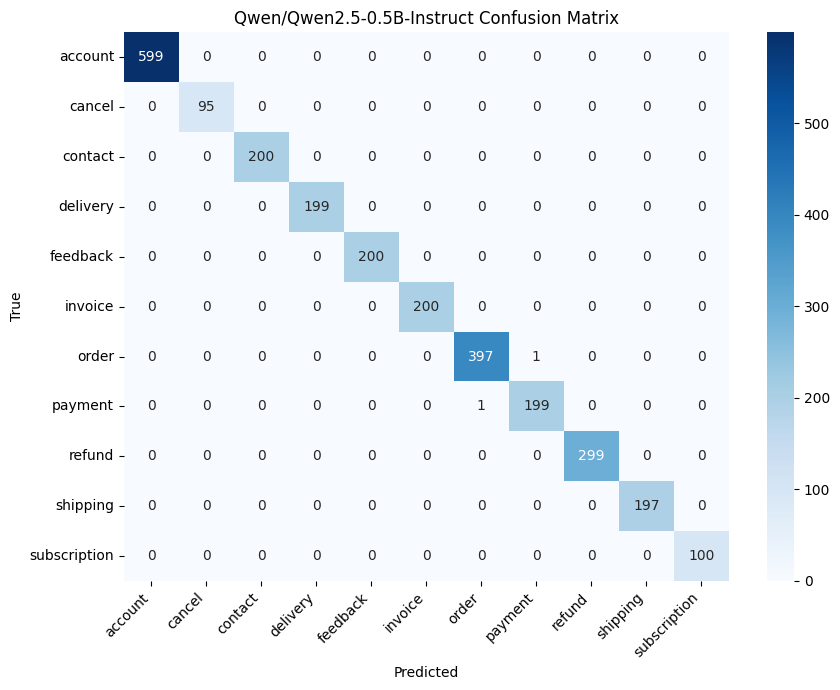

In [21]:
plot_confusion_matrix_heatmap(dec_labels, dec_predictions,
                               [c.lower() for c in TARGET_CATEGORIES],
                               title=f"{decoder_model_id} Confusion Matrix")


## 7. Comparison

Both cells below are given (pure plotting/table), they assume the variable names
used throughout this notebook (`enc_*` / `dec_*`). If you renamed anything,update the references accordingly.

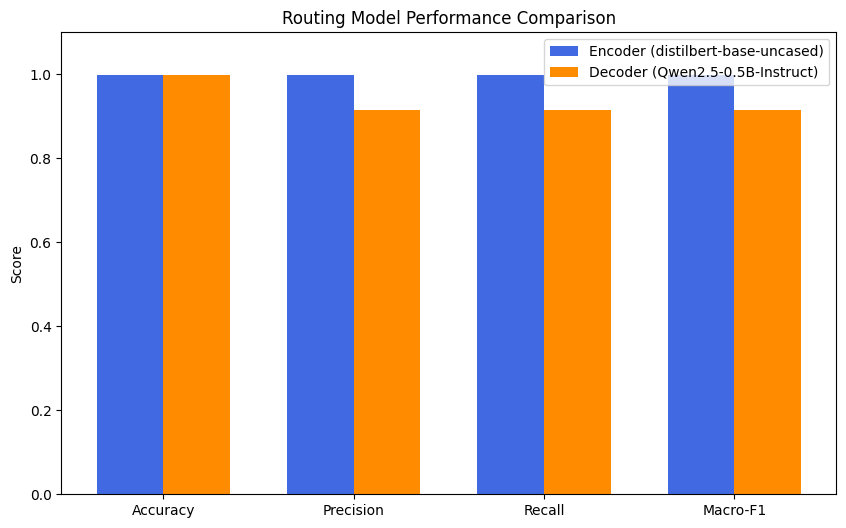

In [22]:
# Comparison bar chart
metrics_names = ["Accuracy", "Precision", "Recall", "Macro-F1"]
enc_scores = [enc_acc, enc_prec, enc_rec, enc_f1]
dec_scores = [dec_acc, dec_prec, dec_rec, dec_f1]

x = np.arange(len(metrics_names))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(x - width/2, enc_scores, width, label=f"Encoder ({encoder_model_id.split('/')[-1]})", color="royalblue")
ax.bar(x + width/2, dec_scores, width, label=f"Decoder ({decoder_model_id.split('/')[-1]})", color="darkorange")
ax.set_ylabel("Score")
ax.set_title("Routing Model Performance Comparison")
ax.set_xticks(x)
ax.set_xticklabels(metrics_names)
ax.legend()
plt.ylim(0, 1.1)
plt.show()

In [23]:
# Dedicated comparison table with measured values
# fill in by running the cells above
comparison_table = pd.DataFrame({
    "Metric": ["Precision", "Recall", "Macro-F1", "Accuracy",
               "Peak GPU Memory (MB)", "Inference Latency (ms/query)"],
    f"Encoder ({encoder_model_id})": [enc_prec, enc_rec, enc_f1, enc_acc, enc_peak_mem, enc_latency],
    f"Decoder SLM ({decoder_model_id}{' + LoRA' if USE_LORA else ''})":
        [dec_prec, dec_rec, dec_f1, dec_acc, dec_peak_mem, dec_latency],
})
comparison_table

,Metric,Encoder (distilbert/distilbert-base-uncased),Decoder SLM (Qwen/Qwen2.5-0.5B-Instruct + LoRA)
0,Precision,0.999320,0.916041
1,Recall,0.999318,0.915832
2,Macro-F1,0.999318,0.915936
3,Accuracy,0.999256,0.998884
4,Peak GPU Memory (MB),787.583496,815.831543
5,Inference Latency (ms/query),4.950154,289.126971


## 8. Recommendation

**To: Engineering Lead, ShopAssist AI**

To the Engineering Lead at ShopAssist AI, I recommend deploying the DistilBERT encoder-only router as the production default. On the held-out test set, it achieved a macro-F1 of **0.9993** and accuracy of **0.9993**, while averaging only **4.95 ms per query** for single-example inference. Its peak inference GPU memory was **787.58 MB**. The Qwen2.5-0.5B-Instruct + LoRA router was also highly accurate, with a corrected 11-class macro-F1 of **0.9992** and accuracy of **0.9989**, but it required **289.13 ms per query** and **815.83 MB** of peak GPU memory. For a routing layer that runs before every support request, the encoder therefore offers essentially the same predictive quality with far lower latency and slightly lower memory use, making it much more cost-efficient at scale. The main production risk is distribution shift: new products, unusual wording, ambiguous requests, or out-of-scope messages may be routed confidently to the wrong agent. I would monitor confidence scores, per-class precision/recall and macro-F1 on regularly sampled human-labeled traffic, confusion patterns, and the rate of low-confidence or corrected handoffs, with alerts when these metrics drift from the validation baseline.


## 9. Reflection

### Q1: On what transfers from pretraining

Pretraining supplied the general language knowledge that made both models useful before they saw the ShopAssist labels. The encoder already had representations for word meaning, syntax, context, negation, paraphrases, and relationships between phrases such as “charged twice,” “cancel my order,” or “change my address.” The decoder additionally brought next-token generation ability and instruction-following behavior from its language-model pretraining. Fine-tuning did not need to teach English from the beginning; it had to teach the task-specific mapping from those existing representations to the 11 ShopAssist routing categories. For DistilBERT, the classification head had to learn the decision boundaries that connect the first-token representation to ACCOUNT, ORDER, PAYMENT, REFUND, and the other agents. For Qwen, fine-tuning had to teach the model to convert a support message into exactly the required category label rather than produce a normal conversational answer. In short, pretraining transferred broad linguistic and semantic competence, while fine-tuning learned the routing policy, domain-specific label boundaries, and output format.

### Q2: On Handling Chit-Chat Queries

A message such as **“Hey! How’s it going?”** is out of distribution because the training target contains only the 11 support categories and no CHITCHAT/OTHER class. The encoder-only model must still take an argmax over its 11 logits, so it will always route the message to some agent even when none is appropriate. That makes its failure hard to detect unless we examine confidence or uncertainty. The decoder-only model is also prompted to choose one of the fixed labels, so after fine-tuning it will usually force the message into the closest category; however, because it generates text, it can also produce an unmatched or non-label output. With an output validator, that failure can be detected and rejected, so the decoder can fail slightly more gracefully. In production, I would not rely on either behavior alone. I would add an **OTHER/CHITCHAT/OOD** route and train it with greetings, acknowledgements, spam, and unrelated messages. I would also add a rejection policy: low-confidence encoder predictions or low-probability/invalid decoder outputs would be sent to a general assistant or human triage queue. Monitoring the rejection rate and reviewing sampled rejected messages would help discover new intents that should later become explicit classes.
